<a href="https://colab.research.google.com/github/Harmanjot1978/EDA-PROJECT/blob/main/NYC.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [199]:
# Import Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')


In [200]:
from google.colab import files
df = files.upload()

Saving AB_NYC_2019.csv.zip to AB_NYC_2019.csv (7).zip


In [201]:
df = pd.read_csv("AB_NYC_2019.csv.zip")

In [202]:
df.head()

,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365
0,2539,Clean & quiet apt home by the park,2787,John,Brooklyn,Kensington,40.64749,-73.97237,Private room,149,1,9,2018-10-19,0.21,6,365
1,2595,Skylit Midtown Castle,2845,Jennifer,Manhattan,Midtown,40.75362,-73.98377,Entire home/apt,225,1,45,2019-05-21,0.38,2,355
2,3647,THE VILLAGE OF HARLEM....NEW YORK !,4632,Elisabeth,Manhattan,Harlem,40.80902,-73.94190,Private room,150,3,0,NaN,NaN,1,365
3,3831,Cozy Entire Floor of Brownstone,4869,LisaRoxanne,Brooklyn,Clinton Hill,40.68514,-73.95976,Entire home/apt,89,1,270,2019-07-05,4.64,1,194
4,5022,Entire Apt: Spacious Studio/Loft by central park,7192,Laura,Manhattan,East Harlem,40.79851,-73.94399,Entire home/apt,80,10,9,2018-11-19,0.10,1,0


In [203]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48895 entries, 0 to 48894
Data columns (total 16 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   id                              48895 non-null  int64  
 1   name                            48879 non-null  object 
 2   host_id                         48895 non-null  int64  
 3   host_name                       48874 non-null  object 
 4   neighbourhood_group             48895 non-null  object 
 5   neighbourhood                   48895 non-null  object 
 6   latitude                        48895 non-null  float64
 7   longitude                       48895 non-null  float64
 8   room_type                       48895 non-null  object 
 9   price                           48895 non-null  int64  
 10  minimum_nights                  48895 non-null  int64  
 11  number_of_reviews               48895 non-null  int64  
 12  last_review                     

In [204]:
df.tail()

,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365
48890,36484665,Charming one bedroom - newly renovated rowhouse,8232441,Sabrina,Brooklyn,Bedford-Stuyvesant,40.67853,-73.94995,Private room,70,2,0,NaN,NaN,2,9
48891,36485057,Affordable room in Bushwick/East Williamsburg,6570630,Marisol,Brooklyn,Bushwick,40.70184,-73.93317,Private room,40,4,0,NaN,NaN,2,36
48892,36485431,Sunny Studio at Historical Neighborhood,23492952,Ilgar & Aysel,Manhattan,Harlem,40.81475,-73.94867,Entire home/apt,115,10,0,NaN,NaN,1,27
48893,36485609,43rd St. Time Square-cozy single bed,30985759,Taz,Manhattan,Hell's Kitchen,40.75751,-73.99112,Shared room,55,1,0,NaN,NaN,6,2
48894,36487245,Trendy duplex in the very heart of Hell's Kitchen,68119814,Christophe,Manhattan,Hell's Kitchen,40.76404,-73.98933,Private room,90,7,0,NaN,NaN,1,23


In [205]:
df.duplicated().sum()

np.int64(0)

In [206]:
df.drop_duplicates(inplace=True)

In [207]:
df.duplicated().sum()

np.int64(0)

In [208]:
df.isnull().sum()

,0
id,0
name,16
host_id,0
host_name,21
neighbourhood_group,0
neighbourhood,0
latitude,0
longitude,0
room_type,0
price,0


In [209]:
df['latitude'] = df['latitude'].fillna(df['latitude'].mean())
df['longitude'] = df['longitude'].fillna(df['longitude'].mean())
df['reviews_per_month'] = df['reviews_per_month'].fillna(df['reviews_per_month'].mean())


In [210]:
df['last_review'] = pd.to_datetime(df['last_review'])
df['last_review'] = df['last_review'].fillna(df['last_review'].mean())

In [211]:
df.isnull().sum()

,0
id,0
name,16
host_id,0
host_name,21
neighbourhood_group,0
neighbourhood,0
latitude,0
longitude,0
room_type,0
price,0


In [212]:
df.drop('name', axis=1, inplace=True)
df.drop('host_name', axis=1, inplace=True)
df.drop('id', axis=1, inplace=True)

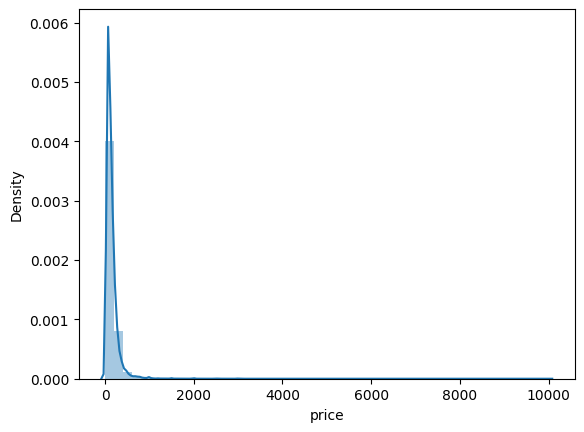

In [213]:
# Univariate Analysis
sns.distplot(df['price'])
plt.show()

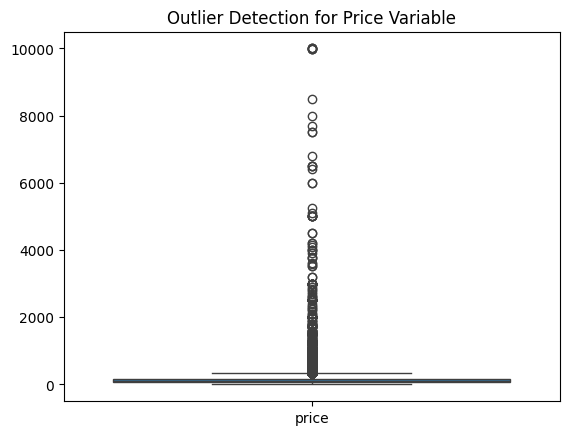

In [214]:
#Outlier Treatment
sns.boxplot(df[['price']])
plt.title("Outlier Detection for Price Variable")
plt.show()

In [215]:
# Outlier Treatment
Q1 = df['price'].quantile(0.25)
Q3 = df['minimum_nights'].quantile(0.75)
IQR = Q3 - Q1

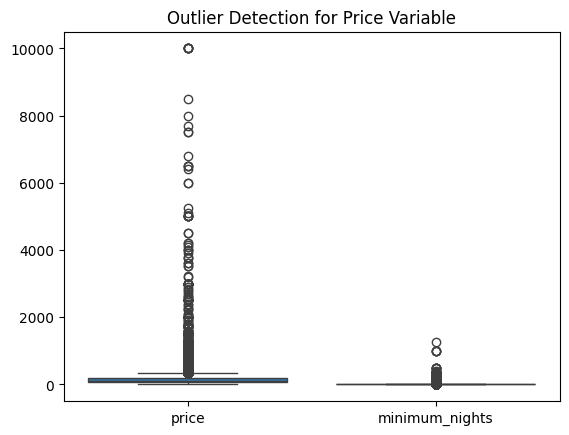

In [216]:
#Outlier Treatment
sns.boxplot(df[['price','minimum_nights']])
plt.title("Outlier Detection for Price Variable")
plt.show()

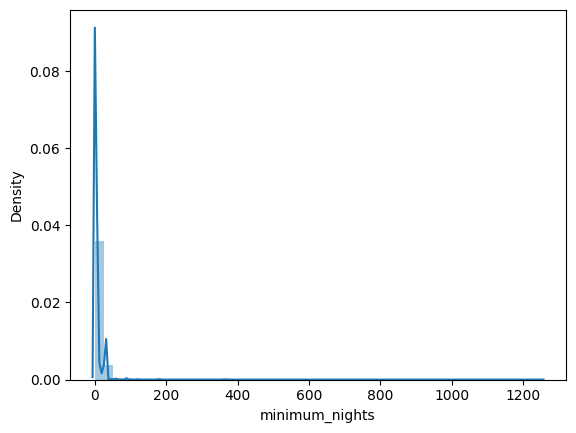

In [217]:
# Univariate Analysis
sns.distplot(df['minimum_nights'])
plt.show()

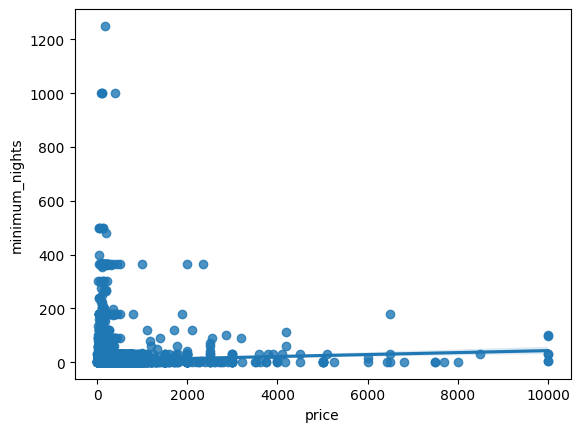

In [218]:
# Bivariate Analysis
sns.regplot(x='price', y='minimum_nights', data=df)
plt.show()

In [219]:
# Seperate X and Y
x = df.drop('price', axis=1)
y = df['price']


In [220]:
from sklearn.model_selection import train_test_split
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)

In [221]:
from sklearn.linear_model import LinearRegression

# Exclude 'minimum_nights' from training data, leaving only 'number_of_reviews' as feature
x_train_selected = x_train[['number_of_reviews']]

model = LinearRegression()
model.fit(x_train_selected, y_train)

LinearRegression()

In [222]:
y_pred = model.predict(x_test[['number_of_reviews']])

In [223]:
print(y_pred)


[143.24975283 160.08961384 155.4722326  ... 158.73156053 160.08961384
 152.48451532]


In [224]:
results = pd.DataFrame({'Actual': y_test, 'Predicted': y_pred})
print(results)

       Actual   Predicted
879        89  143.249753
44383      30  160.089614
15394     120  155.472233
43230     470  158.731561
16332     199  151.941294
...       ...         ...
20477     215  155.200622
44969     100  160.089614
36577      70  158.731561
11477     500  160.089614
1023      125  152.484515

[9779 rows x 2 columns]


In [225]:
from sklearn.metrics import mean_squared_error, r2_score
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)
print("Mean Squared Error:", mse)
print("R-squared:", r2)

Mean Squared Error: 44187.87692500988
R-squared: 0.0011384040370704396


In [226]:
new_price = model.predict([[100]])
print("Predicted Price:", new_price)

Predicted Price: [132.9285477]


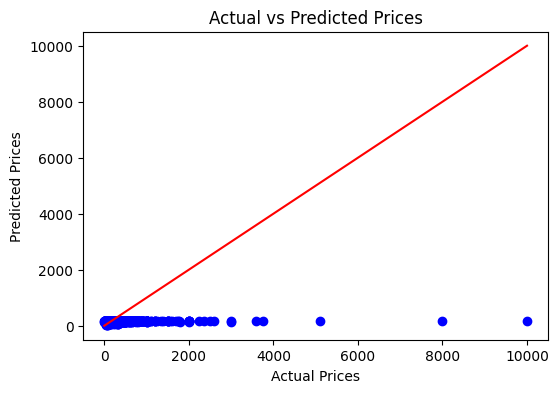

In [227]:
# 1. Calculate the errors (residuals)
errors = y_test - y_pred

# -------------------------------------------------------------
# TASK 7.1: Actual vs Predicted Scatter Plot
# -------------------------------------------------------------
plt.figure(figsize=(6, 4))
plt.scatter(y_test, y_pred, color="blue")

# Add standard diagonal line for perfect prediction
plt.plot([min(y_test), max(y_test)], [min(y_test), max(y_test)], color="red")

plt.title("Actual vs Predicted Prices")
plt.xlabel("Actual Prices")
plt.ylabel("Predicted Prices")
plt.show()

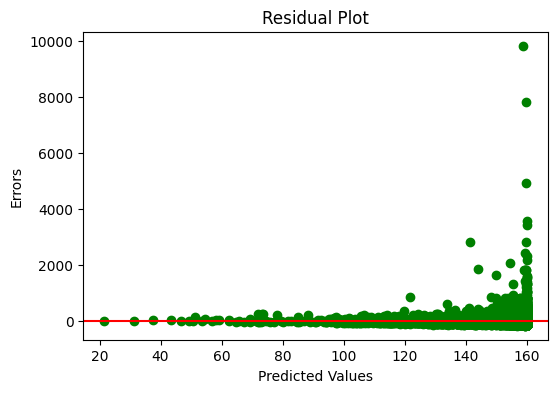

In [228]:
# TASK 7.2: Residual Plot (Errors vs Predicted)
# -------------------------------------------------------------
plt.figure(figsize=(6, 4))
plt.scatter(y_pred, errors, color="green")

# Add a simple horizontal baseline at 0
plt.axhline(y=0, color="red")

plt.title("Residual Plot")
plt.xlabel("Predicted Values")
plt.ylabel("Errors")
plt.show()

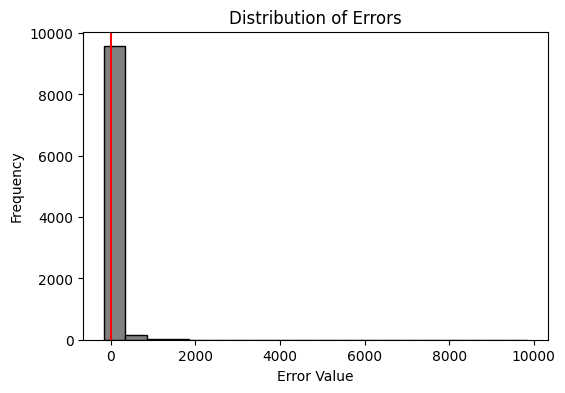

In [229]:
# TASK 7.2: Simple Error Histogram
# -------------------------------------------------------------
plt.figure(figsize=(6, 4))
plt.hist(errors, bins=20, color="gray", edgecolor="black")
plt.axvline(x=0, color="red")

plt.title("Distribution of Errors")
plt.xlabel("Error Value")
plt.ylabel("Frequency")
plt.show()

In [230]:
# the model performs better on cheap listings.
#
# Why:
#
# • The graph shows it: In the residual plot, the dots on the left side (cheap listings) are much closer to the red line. This means the model's guesses were very close to the real prices. On the right side (expensive listings), the dots are spread far apart, showing bigger mistakes.
# • Cheap houses are easier to predict: Lower-priced properties usually follow standard market prices based on basic things like size and location, which makes them easier for the model to learn.
# • Expensive houses have unique features: Luxury properties often have high prices due to subjective things like custom renovations, views, or high-end finishes. The model doesn't know about these special details, so it struggles to guess their prices accurately.